In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

In [36]:
now = 1000
start_of_operations = 480
time_between_operations = 480
duration_of_operations = 480

if now % time_between_operations < duration_of_operations:
    print('work')
else:
    print('pause')


work


In [23]:
now = 1399
time_between_operations = 480
duration_of_operations = 480


if (now % 1440) < (duration_of_operations + time_between_operations):
    print('work')
else:
    print('pause')

pause


In [54]:
transactio = pd.read_excel('../data/output/transactions.xlsx')

filtered_df = transactio[transactio['state'] != 'Missed']

In [55]:
filtered_df.to_excel('../data/output/transactions.xlsx')

In [88]:
_random = np.random.RandomState(None)
_random.binomial(1, 0.5, 1)

array([1])

In [27]:
trips = pd.read_csv('../data/demand/shared_vehicle_trips_berlin.csv')
trips['vehicleType'] = trips['vehicleType'].replace({'bicycle': 'bikes', 'bycicle': 'bikes'})
trips['vehicleType'] = trips['vehicleType'].replace({'nextbike': 'tier'})


/var/folders/h1/19m73vv146ngz4z67pq_kqy80000gn/T/ipykernel_35418/3900198160.py:1: DtypeWarning: Columns (4,21,22,57) have mixed types. Specify dtype option on import or set low_memory=False.
  trips = pd.read_csv('../data/demand/shared_vehicle_trips_berlin.csv')


In [28]:
trips.head()

,id,provider,city,vehicleType,model,datetime_start,date_start,time_start,datetime_end,date_end,...,h3_start_8,h3_end_8,h3_start_9,h3_end_9,hour_of_day,time_bucket_12h,time_bucket_8h,time_bucket_6h,time_bucket_4h,time_bucket_2h
0,13001nextbike,nextbike,berlin,bikes,NaN,2019-10-04 15:08:00+02:00,20191004,1505,2019-10-04 15:36:00+02:00,20191004,...,881f1d4d2dfffff,881f18b2c5fffff,891f1d4d2cbffff,891f18b2c53ffff,15,1,1,2,3,7
1,13001nextbike,nextbike,berlin,bikes,NaN,2019-10-06 20:48:00+02:00,20191006,2045,2019-10-06 20:56:00+02:00,20191006,...,881f18b21bfffff,881f18b21bfffff,891f18b21b3ffff,891f18b21a3ffff,20,1,2,3,5,10
2,13001nextbike,nextbike,berlin,bikes,NaN,2019-10-07 08:08:00+02:00,20191007,805,2019-10-07 08:29:00+02:00,20191007,...,881f18b21bfffff,881f1d48b7fffff,891f18b21a3ffff,891f1d48b73ffff,8,0,1,1,2,4
3,13001nextbike,nextbike,berlin,bikes,NaN,2019-10-07 19:21:00+02:00,20191007,1920,2019-10-07 20:37:00+02:00,20191007,...,881f1d48b7fffff,881f1d4d6dfffff,891f1d48b73ffff,891f1d4d6d7ffff,19,1,2,3,4,9
4,13001nextbike,nextbike,berlin,bikes,NaN,2019-10-09 01:04:00+02:00,20191009,100,2019-10-09 01:11:00+02:00,20191009,...,881f18b24bfffff,881f18b24bfffff,891f18b24a7ffff,891f18b24b7ffff,1,0,0,0,0,0


## Demand

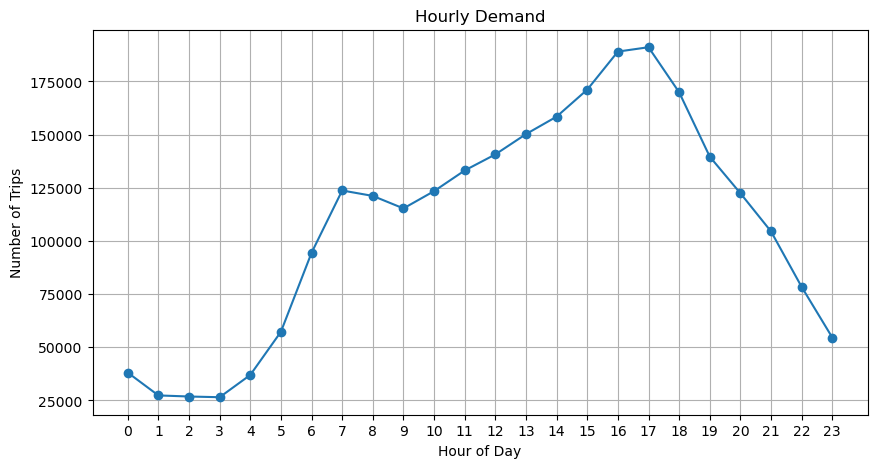

In [29]:
trips['datetime_start'] = pd.to_datetime(trips['datetime_start'], utc=True)
trips['hour_of_day'] = trips['datetime_start'].dt.hour
hourly_demand = trips.groupby('hour_of_day').size()

plt.figure(figsize=(10, 5))
plt.plot(hourly_demand.index, hourly_demand.values, marker='o')
plt.title('Hourly Demand')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')
plt.grid(True)
plt.xticks(range(0, 24))
plt.show()


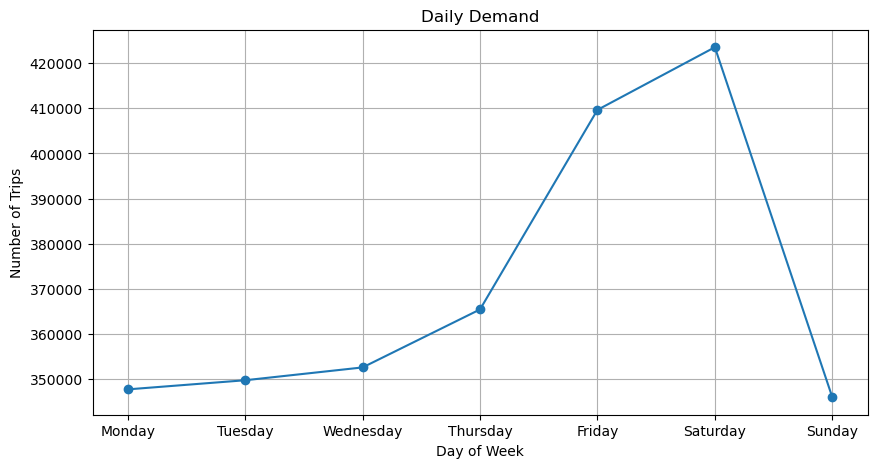

In [30]:
trips['day_of_week'] = trips['datetime_start'].dt.dayofweek
daily_demand = trips.groupby('day_of_week').size()

plt.figure(figsize=(10, 5))
plt.plot(daily_demand.index, daily_demand.values, marker='o')
plt.title('Daily Demand')
plt.xlabel('Day of Week')
plt.ylabel('Number of Trips')
plt.grid(True)
plt.xticks(range(0, 7), ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
plt.show()

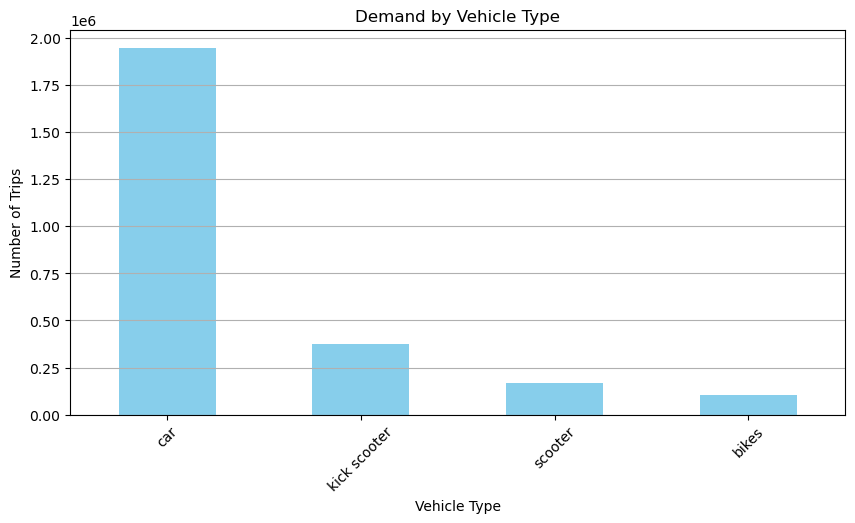

In [31]:
vehicle_demand = trips['vehicleType'].value_counts()

plt.figure(figsize=(10, 5))
vehicle_demand.plot(kind='bar', color='skyblue')
plt.title('Demand by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

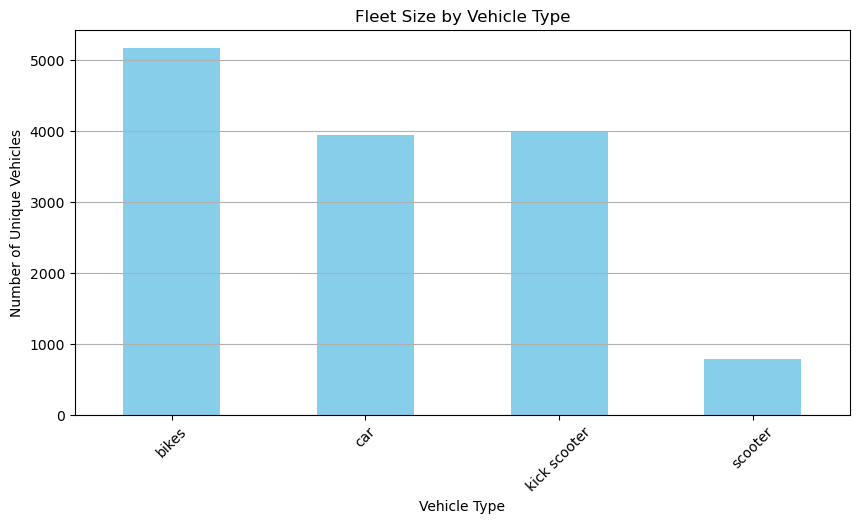

In [32]:
fleet_size = trips.groupby('vehicleType')['id'].nunique()

plt.figure(figsize=(10, 5))
fleet_size.plot(kind='bar', color='skyblue')
plt.title('Fleet Size by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Number of Unique Vehicles')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

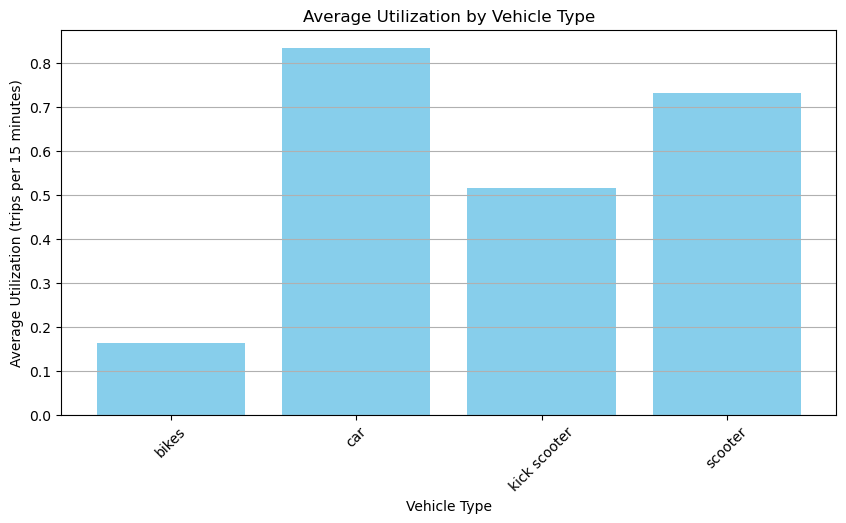

,vehicleType,util_per_hour
0,bikes,0.163835
1,car,0.832955
2,kick scooter,0.514598
3,scooter,0.729776


In [90]:
provider_fleet = trips.groupby(['provider', 'vehicleType'])['id'].nunique().unstack(fill_value=0)

print(provider_fleet)
provider_fleet.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')
plt.title('Fleet Size by Provider and Vehicle Type')
plt.xlabel('Provider')
plt.ylabel('Number of Unique Vehicles')
plt.xticks(rotation=45)
plt.legend(title='Vehicle Type')
plt.grid(axis='y')
plt.show()

/var/folders/h1/19m73vv146ngz4z67pq_kqy80000gn/T/ipykernel_35418/801115926.py:7: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  trips['hour'] = trips['datetime_start'].dt.floor('H')


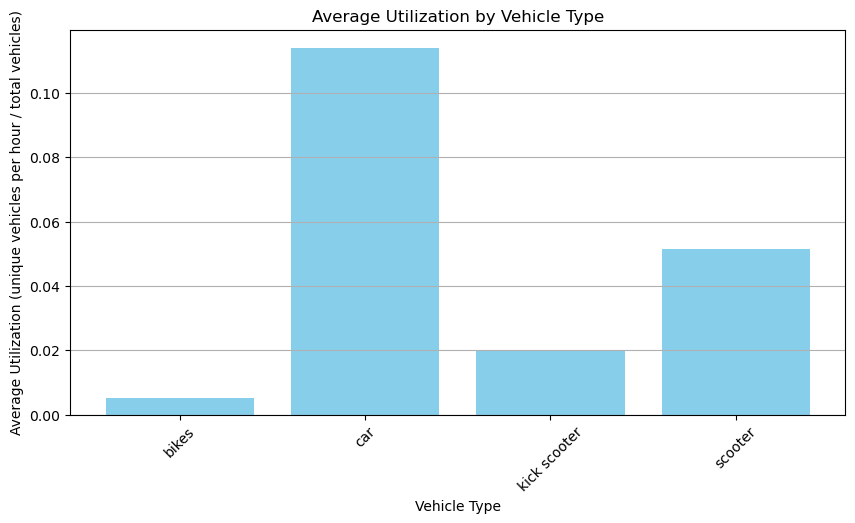

0.047592948647453816


,vehicleType,util_per_hour
0,bikes,0.005295
1,car,0.113882
2,kick scooter,0.019664
3,scooter,0.051531


In [95]:
provider_fleet = trips.groupby(['provider', 'vehicleType'])['id'].nunique().unstack(fill_value=0)

# Sum the number of unique vehicles for each vehicle type
number_of_vehicles = provider_fleet.sum().to_dict()

# Convert the datetime to minutes since start of day for calculation
trips['hour'] = trips['datetime_start'].dt.floor('H')

# Group by vehicle type, vehicle ID, and hour to get the unique count
grouped_df = trips.groupby(['vehicleType', 'id', 'hour']).size().reset_index(name='count')

# Group by vehicle type and hour to get the number of unique vehicles on the road each hour
vehicles_per_hour = grouped_df.groupby(['vehicleType', 'hour'])['id'].nunique().reset_index(name='num_vehicles_per_hour')

# Map the total number of vehicles to the vehicle type
vehicles_per_hour['capacity'] = vehicles_per_hour['vehicleType'].map(number_of_vehicles)

# Calculate the utilization per hour
vehicles_per_hour['util_per_hour'] = vehicles_per_hour['num_vehicles_per_hour'] / vehicles_per_hour['capacity']

# Calculate the average utilization per vehicle type
average_utilization = vehicles_per_hour.groupby('vehicleType')['util_per_hour'].mean().reset_index()

# Plot the average utilization for each vehicle type
plt.figure(figsize=(10, 5))
plt.bar(average_utilization['vehicleType'], average_utilization['util_per_hour'], color='skyblue')
plt.title('Average Utilization by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Average Utilization (unique vehicles per hour / total vehicles)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

# Display the average utilization per vehicle type
print(average_utilization['util_per_hour'].mean())

average_utilization

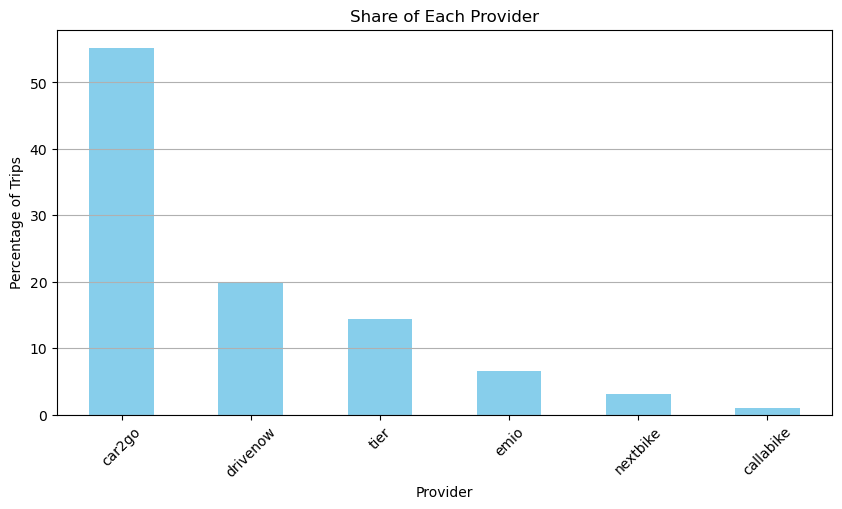

In [35]:
metprovider_share = trips['provider'].value_counts()

# Calculate the percentage share of each provider
provider_share_percentage = (provider_share / provider_share.sum()) * 100

# Plot the share of each provider
plt.figure(figsize=(10, 5))
provider_share_percentage.plot(kind='bar', color='skyblue')
plt.title('Share of Each Provider')
plt.xlabel('Provider')
plt.ylabel('Percentage of Trips')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

## Trips Characteristics

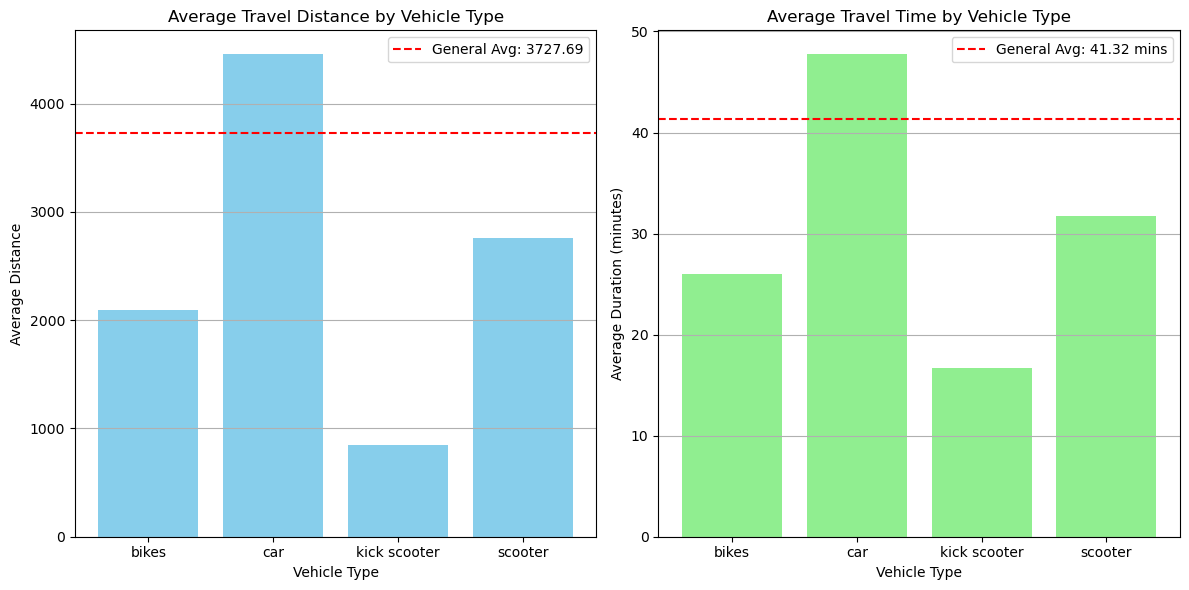

General Average Travel Distance: 3727.69
General Average Travel Time: 41.32 minutes


,vehicleType,distance,duration_minutes
0,bikes,2095.086318,25.957500
1,car,4454.544614,47.724624
2,kick scooter,843.295275,16.683635
3,scooter,2761.139830,31.741556


In [39]:
trips['duration_minutes'] = trips['duration'] / 60

general_avg_distance = trips['distance'].mean()
general_avg_duration = trips['duration_minutes'].mean()

# Calculate the average travel distance and time for each vehicle type
vehicle_type_avg = trips.groupby('vehicleType').agg({'distance': 'mean', 'duration_minutes': 'mean'}).reset_index()

# Plot the average travel distance for each vehicle type
plt.figure(figsize=(12, 6))

# Subplot for average travel distance
plt.subplot(1, 2, 1)
plt.bar(vehicle_type_avg['vehicleType'], vehicle_type_avg['distance'], color='skyblue')
plt.axhline(y=general_avg_distance, color='r', linestyle='--', label=f'General Avg: {general_avg_distance:.2f}')
plt.title('Average Travel Distance by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Average Distance')
plt.legend()
plt.grid(axis='y')

# Subplot for average travel duration
plt.subplot(1, 2, 2)
plt.bar(vehicle_type_avg['vehicleType'], vehicle_type_avg['duration_minutes'], color='lightgreen')
plt.axhline(y=general_avg_duration, color='r', linestyle='--', label=f'General Avg: {general_avg_duration:.2f} mins')
plt.title('Average Travel Time by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Average Duration (minutes)')
plt.legend()
plt.grid(axis='y')

plt.tight_layout()
plt.show()

# Display the general average travel distance and time
print(f"General Average Travel Distance: {general_avg_distance:.2f}")
print(f"General Average Travel Time: {general_avg_duration:.2f} minutes")

# Display the average travel distance and time for each vehicle type
vehicle_type_avg